
# Paddy Disease Classification — **PyTorch + timm**

This is a **minimal, beginner-friendly** image classification pipeline using **PyTorch** and **[timm](https://github.com/huggingface/pytorch-image-models)** (Torch Image Models).  
Typical steps:

1) Setup & configuration  
2) Dataset & transforms (train/valid split)  
3) Model (transfer learning with `timm.create_model`)  
4) Training loop (loss/optimizer)  
5) Evaluation & confusion matrix  
6) (Optional) Inference on test set + `submission.csv`

> **Note:** Point `DATA_DIR` to your local Kaggle Paddy dataset. 


## 1) Setup & Configuration

In [7]:

# If timm isn't installed, uncomment:
# !pip install timm --quiet

import os, random, math, time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, random_split

from torchvision import datasets, transforms
import timm

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed(42)

DATA_DIR = Path("./data/")  
DATA_DIR_TRAIN = Path("./data/train_images/")
 
TRAIN_CSV = DATA_DIR / 'train.csv'
TRAIN_IMG_ROOT = DATA_DIR   / 'train_images'
torch.cuda.set_device(2) #only do this if you have multiple GPUs and you want a particular unused one
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

import matplotlib.pyplot as plt

#this makes sure that colab instances running this notebook can get to included utils_kp.py
try:
    import utils_kp as ut
except ModuleNotFoundError:
    !wget https://raw.githubusercontent.com/CNUClasses/471_code/master/week6/utils_kp.py
import utils_kp as ut
#  https://raw.githubusercontent.com/ultralytics/main/notebooks/how-to-train-ultralytics-yolo-on-construction-ppe-detection-dataset.ipynb


# lr=0.01 #start with this one (its too high see lr finder below)
lr=2e-3 #lr finder approved this one

NUM_EPOCHS=5

Device: cuda


## 1) Get Data

Data comes from <strong><a href="https://www.kaggle.com/competitions/paddy-disease-classification">Paddy Doctor: Paddy Disease Classification</a></strong>.  A Kaggle competition whose goal is to identify the type of disease present in rice paddy leaf images. You can download it directly after signing up for a <a href="https://www.kaggle.com/">Kaggle</a> account.<br>

### (Optional)
A better way to get the data is through the <strong><a href="https://www.kaggle.com/docs/api">Kaggle CLI (command line interface)</a></strong>.<br>
It lets you programatically interact with Kaggle (get/browse datasets and competitions and submit results)<br>
BTW- you need to have an API key in order to use the CLI, to get one:<br>
Scroll to the API section in your Account settings and click the Create New API Token button.<br>
Kaggle will generate a JSON file named kaggle.json and prompt you to save the file to your computer.<br>
Put this file in the ~/.kaggle directory on your machine, make sure its only readable by you (chmod 600 /root/.kaggle/kaggle.json)<br>
The CLI looks in this place for your key.<br>



In [8]:
# !pip install --upgrade kaggle  #upgrade or install kaggle CLI
# !mkdir -p ~/.kaggle  #create a place for kaggle.json file
# get the key from above, download it and place it in ~/.kaggle/kaggle.json

# the \" below ensures the " marks are written to the file
# {"username":"kperkins411","key":"Your_key_here"}
# !echo "{\"username\":\"youruserid\",\"key\":\"yourkey\"}" > ~/.kaggle/kaggle.json


In [9]:
# !kaggle datasets list #active competitions
!kaggle datasets list -s paddy-disease-classification  #the one we want
# !kaggle competitions download -c paddy-disease-classification #get it
# !unzip paddy-disease-classification.zip -d ./data/  #unzip it

ref                                                                 title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
------------------------------------------------------------------  -------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
imbikramsaha/paddy-doctor                                           Paddy Disease Classification all 480*640 px image   1094204760  2022-08-22 11:31:09.817000           3932         33  0.8235294        
dasa7753912/new-paddy-doctor-paddy-disease-classification           New Paddy Doctor: Paddy Disease Classification      2331834459  2024-05-05 17:36:57.253000            438          1  0.5294118        
shuvokumarbasak4004/paddy-algae-monitoring-dataset-bd               Paddy Algae Monitoring Dataset BD                    209830055  2026-02-28 09:15:17.227000             20         14


## 2) Create datasets with timm transforms 

Want train, valid and test sets (most data for train, choose 80%,10%,10%)

If your data follows the Kaggle layout (`train_images/` and `train.csv` with `image_id,label`), use this dataset class.  



In [10]:
import pprint
import timm.data
pp = pprint.PrettyPrinter(indent=4)

# MODEL_NAME = "resnet18"  # try: 'efficientnet_b0', 'convnext_tiny', 'mobilenetv3_large_100', ...
MODEL_NAME = 'convnext_tiny'
config = timm.data.resolve_data_config({}, model=MODEL_NAME)
train_tfms = timm.data.create_transform(**config, is_training=True, hflip=0.5, auto_augment=None)
valid_tfms = timm.data.create_transform(**config, is_training=False)

pp.pprint(config)

{   'crop_mode': 'center',
    'crop_pct': 0.875,
    'input_size': (3, 224, 224),
    'interpolation': 'bicubic',
    'mean': (0.485, 0.456, 0.406),
    'std': (0.229, 0.224, 0.225)}


In [11]:
from sklearn.model_selection import StratifiedShuffleSplit

full_ds = datasets.ImageFolder(DATA_DIR_TRAIN, transform=train_tfms)
n_total = len(full_ds)
print(f"Total images: {n_total}")

#want 20% valid and test, 80% train
n_valid= int(0.2 * n_total)
n_train = n_total - n_valid 

targets = np.array(full_ds.targets)
sss = StratifiedShuffleSplit(n_splits=1, test_size=n_valid, random_state=42)
train_idx, valid_idx = next(sss.split(np.arange(n_total), targets))

train_ds = torch.utils.data.Subset(full_ds, train_idx)
valid_ds = torch.utils.data.Subset(full_ds, valid_idx)
#should be stratified split, but close enough for now
# train_ds, valid_ds = random_split(full_ds, [n_train, n_valid], generator=torch.Generator().manual_seed(42))
print(f"Train images: {len(train_ds)}")
print(f"Valid and Test images: {len(valid_ds)}")


Total images: 10407
Train images: 8326
Valid and Test images: 2081


In [12]:
len(valid_idx)

2081

In [13]:
# Split valid_idx further into valid (10%) and test (10%) using StratifiedShuffleSplit
valid_targets = targets[valid_idx]

sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
valid_sub_idx, test_sub_idx = next(sss2.split(np.arange(len(valid_idx)), valid_targets))
# print(f"Valid subset indices: {valid_sub_idx}")
# print(f"Test subset indices: {test_sub_idx}")

final_valid_idx = valid_idx[valid_sub_idx]
final_test_idx = valid_idx[test_sub_idx]

#already have train_ds from above, now create valid_ds and test_ds
valid_ds = torch.utils.data.Subset(full_ds, final_valid_idx)
test_ds  = torch.utils.data.Subset(full_ds, final_test_idx)

print(f"Train images: {len(train_ds)}")
print(f"Valid images: {len(valid_ds)}")
print(f"Test images: {len(test_ds)}")

Train images: 8326
Valid images: 1040
Test images: 1041


## 3) Create Dataloaders

- Shuffle the training loader; keep validation and test loader deterministic.  
- Adjust `BATCH_SIZE` to fit your GPU/CPU memory.

This is a datascience competition:<br>
the train_images folder contains images with class membership info (in the train.csv file).<br>
the test_images folder contains images that your model infers membership on.  These inferences are bundled into a file (see sample_submission.csv) which is submitted for ranking  

In [14]:
BATCH_SIZE = 512
train_images = DATA_DIR / "train_images"
train_csv    = DATA_DIR / "train.csv"
class_names = list(full_ds.class_to_idx.keys())
num_classes = len(class_names)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE*2, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE*2, shuffle=False, num_workers=2, pin_memory=True)

# print(f"Classes ({num_classes}):", class_names[:10], "..." if num_classes>10 else "")
print("Train/Valid/Test sizes:", len(train_ds), len(valid_ds), len(test_ds))


Train/Valid/Test sizes: 8326 1040 1041


### Look at a few of the images

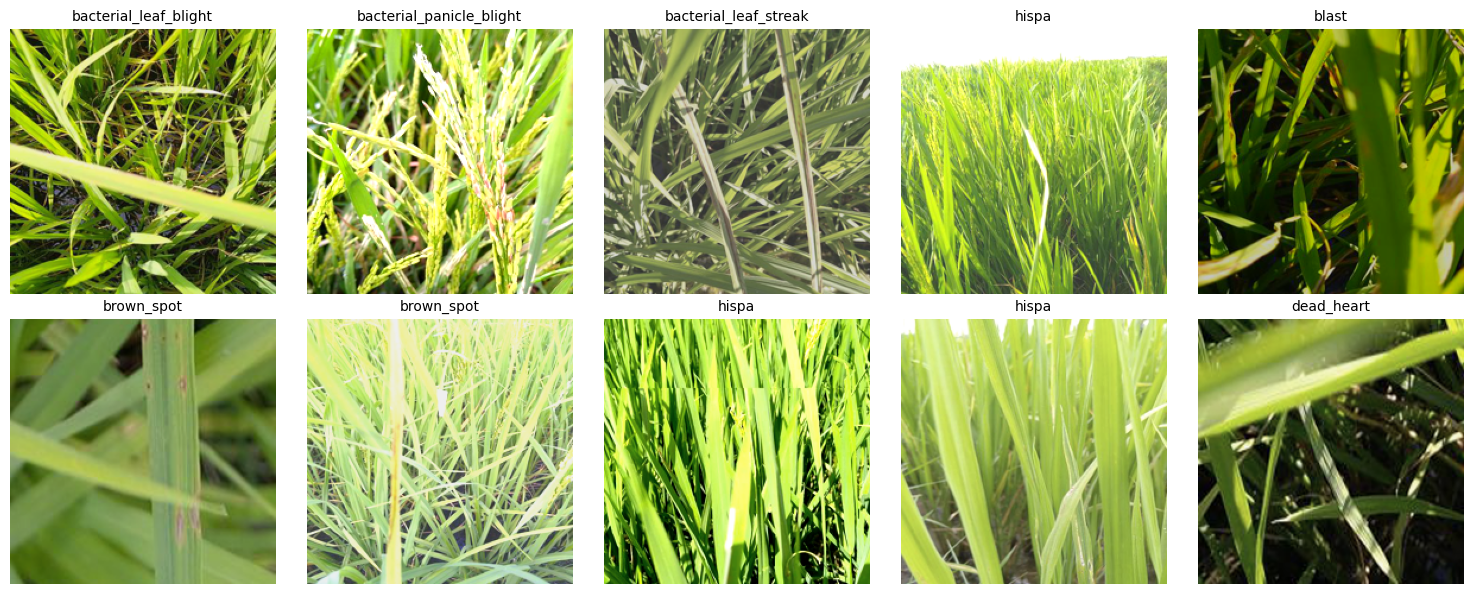

In [15]:
# Display first 10 images + class names from train_loader
# Uses existing variables: train_loader, class_names, config, plt, np, torch

batch = next(iter(train_loader))
xb, yb = batch
num = min(10, xb.size(0))

imgs = xb[:num].clone()  # shape: (num, 3, H, W)
labels_idx = yb[:num].tolist()
labels = [class_names[i] for i in labels_idx]

# un-normalize using config mean/std (expects (3,) tuples)
mean = torch.tensor(config['mean']).view(3, 1, 1)
std = torch.tensor(config['std']).view(3, 1, 1)

# imgs are on CPU (from dataloader); if not, move mean/std to same device
mean = mean.to(imgs.device)
std = std.to(imgs.device)

# create subplots (2 rows x 5 cols)
cols = 5
rows = int(np.ceil(num / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = axes.flatten()

for i in range(rows * cols):
    ax = axes[i]
    if i < num:
        img = imgs[i] * std + mean  # unnormalize
        npimg = img.numpy().transpose(1, 2, 0)
        npimg = np.clip(npimg, 0, 1)
        ax.imshow(npimg)
        ax.set_title(labels[i], fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

## 4) Load timm Model (Transfer Learning with **timm**)

- Create a **pretrained** model with `num_classes` = 10 (PaddyDoctor classes).  
- **Warm-up:** freeze backbone; train the classifier head first.



In [16]:
def make_model(model_name, num_classes, device, verbose=False):
    """Create and prepare a timm model for transfer learning.

    This function:
    - expects a timm model name and number of output classes
    - will create a pretrained model (weights from ImageNet)
    - freezes all parameters so the backbone is not trained initially
    - later code will unfreeze the classifier/head only so you can warm-up the head

    Args:
        model_name (str): name of timm model (e.g. 'convnext_tiny')
        num_classes (int): number of output classes for the classifier head
        device (torch.device): device to move the model to
        verbose (bool): print classifier info when True

    Returns:
        torch.nn.Module: the created model

    Example Usage:
        model = make_model('convnext_tiny', 10, device)
    """
    #pre trained =True or you get random weights
    model = timm.create_model(model_name, pretrained=True, num_classes=num_classes)
    if verbose: print("Classifier layer:", model.get_classifier())

    # Freeze backbone; train classifier head first
    for name, p in model.named_parameters():
        p.requires_grad = False

    # Unfreeze classifier / head only (name depends on model family; get via get_classifier())
    clf_name = model.get_classifier()

    #make sure the last classifier layer is trainable
    for name, p in clf_name.named_parameters():
        p.requires_grad = True

    model = model.to(device)
    return model

In [17]:

model=make_model(MODEL_NAME, num_classes, device, True)

Classifier layer: Linear(in_features=768, out_features=10, bias=True)


In [18]:
#check to see the model structure

print(model)

ConvNeXt(
  (stem): Sequential(
    (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (norm): Identity()
            (fc2): Linear(in_features=384, out_features=96, bias=True)
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)


In [22]:
#make sure just training the last layer
for name, p in model.named_parameters():
    print (f'Name={name},p.shape={p.shape}, p.requires_grad = {p.requires_grad}')


Name=stem.0.weight,p.shape=torch.Size([96, 3, 4, 4]), p.requires_grad = False
Name=stem.0.bias,p.shape=torch.Size([96]), p.requires_grad = False
Name=stem.1.weight,p.shape=torch.Size([96]), p.requires_grad = False
Name=stem.1.bias,p.shape=torch.Size([96]), p.requires_grad = False
Name=stages.0.blocks.0.gamma,p.shape=torch.Size([96]), p.requires_grad = False
Name=stages.0.blocks.0.conv_dw.weight,p.shape=torch.Size([96, 1, 7, 7]), p.requires_grad = False
Name=stages.0.blocks.0.conv_dw.bias,p.shape=torch.Size([96]), p.requires_grad = False
Name=stages.0.blocks.0.norm.weight,p.shape=torch.Size([96]), p.requires_grad = False
Name=stages.0.blocks.0.norm.bias,p.shape=torch.Size([96]), p.requires_grad = False
Name=stages.0.blocks.0.mlp.fc1.weight,p.shape=torch.Size([384, 96]), p.requires_grad = False
Name=stages.0.blocks.0.mlp.fc1.bias,p.shape=torch.Size([384]), p.requires_grad = False
Name=stages.0.blocks.0.mlp.fc2.weight,p.shape=torch.Size([96, 384]), p.requires_grad = False
Name=stages.0.bl


## 5) Optimizer & loss 

Predicting a class, use cross entropy<br>
Optimizer-> AdamW 


In [23]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)

# 6) Training & validation loop

- Log train/valid **loss** and **accuracy** per epoch.  

In [24]:
%%time 

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb) #loss is the avearege over the batch (so multiply by batch size below)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return total_loss/total, correct/total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)  #loss is the avearege over the batch (so multiply by batch size below)
        total_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return total_loss/total, correct/total

def train_and_evaluate(model, train_loader, valid_loader, optimizer, criterion, num_epochs=10):
    for epoch in range(1, num_epochs + 1):
        # Train for one epoch
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)

        # Evaluate on validation set
        va_loss, va_acc = evaluate(model, valid_loader, criterion)
        print(f"Epoch {epoch:02d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | valid loss {va_loss:.4f} acc {va_acc:.3f}")

train_and_evaluate(model, train_loader, valid_loader, optimizer, criterion, num_epochs=NUM_EPOCHS)


Epoch 01 | train loss 1.7772 acc 0.399 | valid loss 1.4820 acc 0.494
Epoch 02 | train loss 1.3100 acc 0.561 | valid loss 1.2325 acc 0.559
Epoch 03 | train loss 1.1626 acc 0.607 | valid loss 1.1490 acc 0.603
Epoch 04 | train loss 1.0808 acc 0.637 | valid loss 1.0874 acc 0.611
Epoch 05 | train loss 1.0382 acc 0.653 | valid loss 1.1105 acc 0.625
CPU times: user 43.5 s, sys: 9.61 s, total: 53.1 s
Wall time: 3min 56s


### (Optional) Fine-tune the whole network

After warming up the head, unfreeze the backbone and fine-tune at a **smaller LR** (usually lr/10)

In [25]:
%%time 

# train the whole thing (unfreeze all layers)
for p in model.parameters():
    p.requires_grad = True

#make lr smaller for fine-tuning
lr1=lr/100

#change learning rate for fine-tuning
for g in optimizer.param_groups:
    g['lr'] = lr1
    
train_and_evaluate(model, train_loader, valid_loader, optimizer, criterion, num_epochs=NUM_EPOCHS)


Epoch 01 | train loss 1.0582 acc 0.643 | valid loss 0.8707 acc 0.707
Epoch 02 | train loss 0.7616 acc 0.741 | valid loss 0.7586 acc 0.743
Epoch 03 | train loss 0.6075 acc 0.798 | valid loss 0.6100 acc 0.793
Epoch 04 | train loss 0.5340 acc 0.826 | valid loss 0.5917 acc 0.799
Epoch 05 | train loss 0.4706 acc 0.840 | valid loss 0.6166 acc 0.788
CPU times: user 2min 4s, sys: 8.37 s, total: 2min 13s
Wall time: 4min 6s


## 7) Save / Load model

In [16]:

torch.save(model.state_dict(), 'kaggle_paddy_timm_multihead.pth')
print('Saved to kaggle_paddy_timm_multihead.pth')
model.load_state_dict(torch.load('kaggle_paddy_timm_multihead.pth', map_location=device))



Saved to kaggle_paddy_timm_multihead.pth


<All keys matched successfully>

## 8) Evaluation & Confusion Matrix

Evaluate the model on the test_loader.  This is the **only** time the model sees this loader

In [17]:
LOADER=test_loader

@torch.no_grad()
def get_all_preds_targets(model, loader):
    model.eval()
    preds, targs = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        logits = model(xb)
        preds.append(logits.argmax(1).cpu().numpy())
        targs.append(yb.numpy())
    return np.concatenate(preds), np.concatenate(targs)

preds, targs = get_all_preds_targets(model, LOADER)

# Confusion matrix
num_classes = len(class_names)
cm = np.zeros((num_classes, num_classes), dtype=int)
for t, p in zip(targs, preds):
    cm[t, p] += 1

print('Confusion Matrix (6x6 for PaddyDoctor):')
print(cm)

# Per-class metrics
per_class = []
for k in range(num_classes):
    TP = cm[k,k]
    FP = cm[:,k].sum() - TP
    FN = cm[k,:].sum() - TP
    TN = cm.sum() - TP - FP - FN
    prec = TP/(TP+FP) if (TP+FP)>0 else 0.0
    rec  = TP/(TP+FN) if (TP+FN)>0 else 0.0
    f1   = (2*prec*rec)/(prec+rec) if (prec+rec)>0 else 0.0
    per_class.append((prec, rec, f1))

macro_p = float(np.mean([p for p,_,_ in per_class]))
macro_r = float(np.mean([r for _,r,_ in per_class]))
macro_f = float(np.mean([f for _,_,f in per_class]))
overall_acc = float((preds == targs).mean())

print('\nPer-class (precision, recall, f1):')
for name,(p,r,f) in zip(class_names, per_class):
    print(f'{name:>10s}: P={p:.3f} R={r:.3f} F1={f:.3f}')
print(f"\nMacro avg: P={macro_p:.3f} R={macro_r:.3f} F1={macro_f:.3f}")
print(f'Overall Accuracy: {overall_acc:.3f}')


Confusion Matrix (6x6 for PaddyDoctor):
[[ 27   0   0   6   7   0   3   0   0   5]
 [  0  28   0   1   6   0   1   2   0   0]
 [  0   0  31   0   0   1   0   0   1   0]
 [  1   0   0 153   4   0   9   2   2   3]
 [  1   0   0   5  85   0   1   1   0   3]
 [  0   0   3   3   2 132   0   1   2   1]
 [  1   0   0   8   4   0  46   0   0   3]
 [  2   0   0   6   6   0   4 125   5  12]
 [  0   0   2   5   8   0   3  13 139   7]
 [  0   0   0   5   5   1   4   3   1  90]]

Per-class (precision, recall, f1):
bacterial_leaf_blight: P=0.844 R=0.562 F1=0.675
bacterial_leaf_streak: P=1.000 R=0.737 F1=0.848
bacterial_panicle_blight: P=0.861 R=0.939 F1=0.899
     blast: P=0.797 R=0.879 F1=0.836
brown_spot: P=0.669 R=0.885 F1=0.762
dead_heart: P=0.985 R=0.917 F1=0.950
downy_mildew: P=0.648 R=0.742 F1=0.692
     hispa: P=0.850 R=0.781 F1=0.814
    normal: P=0.927 R=0.785 F1=0.850
    tungro: P=0.726 R=0.826 F1=0.773

Macro avg: P=0.831 R=0.805 F1=0.810
Overall Accuracy: 0.822


# Optional

### Use a learning rate finder to help set initial Learning Rate

For a sweep of learning rates, reinitialize the model for each rate, train for a **few batches**, and save (learning rate, loss). <br>
When done plot the loss versus learning rate, then choose the largest learning rate on the descending slope—just before the loss starts rising.

In [18]:


# For a sweep of learning rates, reinitialize the model for each rate, train for a **few batches**, and save (learning rate, loss). <br>
# When done plot the loss versus learning rate, then choose the largest learning rate on the descending slope—just before the loss starts rising.
class LearningRateFinder:
    """
    Utility class to help find an optimal learning rate for training neural networks.
    This class runs a series of short training loops over a range of learning rates,
    records the average loss for each, and provides a method to plot the results.
    The goal is to help select a learning rate that leads to rapid loss decrease
    without instability.
    Args:
        model_fn (callable): A function that returns a new instance of the model to be trained.
        criterion (callable): The loss function to use for training.
        device (torch.device or str): The device on which to run the model and data.
    Attributes:
        model_fn (callable): Function to instantiate the model.
        criterion (callable): Loss function.
        device (torch.device or str): Device for computation.
        results (list): Stores tuples of (learning rate, average loss).
    Methods:
        run(lr_list, train_loader, num_batches=5):
            Runs training for each learning rate in lr_list for a few batches,
            records the average loss, and stores the results.
        plot():
            Plots the recorded average losses against the learning rates on a log scale.
    
    Example usage:
        lr_candidates = np.logspace(-6, -1, num=8)
        finder = LearningRateFinder(make_model, criterion, device)
        results = finder.run(lr_candidates, train_loader, num_batches=5)
        finder.plot()

        best_lr, best_loss = min(results, key=lambda t: t[1])
        best_lr, best_loss
    
    """

    def __init__(self, model_name, num_classes, criterion, device):
        self.model_name = model_name
        self.num_classes = num_classes  
        self.criterion = criterion
        self.device = device
        self.results = []

    def _reinit(self):
        return make_model(self.model_name, self.num_classes, self.device)

    def run(self, lr_list, train_loader, num_batches=5):
        self.results.clear()
        for lr in lr_list:
            model = self._reinit()
            optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
#            optimizer = torch.optim.Adam(model.parameters(), lr=lr)
            # optimizer = torch.optim.Adam(model.parameters(), lr=lr)
            model.train()
            it = iter(train_loader); losses = []
            for _ in range(num_batches):
                xb, yb = next(it)
                xb, yb = xb.to(self.device), yb.to(self.device)
                optimizer.zero_grad(set_to_none=True)
                logits = model(xb)
                loss = self.criterion(logits, yb)
                loss.backward(); optimizer.step()
                losses.append(loss.item())
            avg_loss = float(np.mean(losses)) if losses else float('nan')
            self.results.append((float(lr), avg_loss))
        return self.results

    def plot(self):
        if not self.results:
            print("No results. Run .run() first."); return
        lrs, losses = zip(*self.results)
        plt.figure()
        plt.plot(lrs, losses, marker='o')
        plt.xscale('log')
        plt.xlabel("Learning Rate"); plt.ylabel("Average Loss (few batches)")
        plt.title("LR Finder — Loss vs Learning Rate"); plt.show()


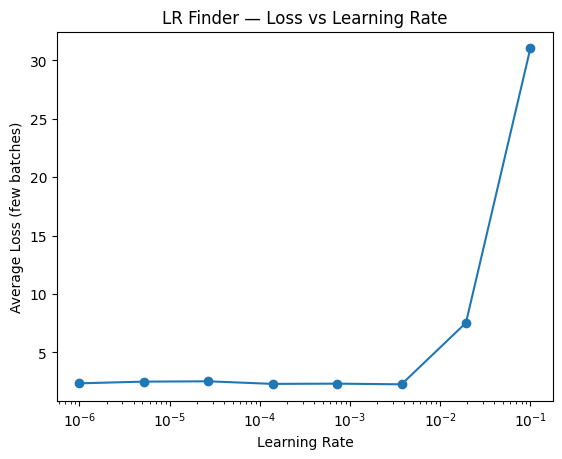

(0.0037275937203149418, 2.2622175216674805)

In [19]:

lr_candidates = np.logspace(-6, -1, num=8)
finder = LearningRateFinder(MODEL_NAME, num_classes, criterion, device)
results = finder.run(lr_candidates, train_loader, num_batches=5)
finder.plot()

best_lr, best_loss = min(results, key=lambda t: t[1])
best_lr, best_loss


## Find and show the top 10 images the model was<br> MOST CONFIDENTLY WRONG on.

"Confidently wrong" = model predicted the wrong class but with high softmax probability.

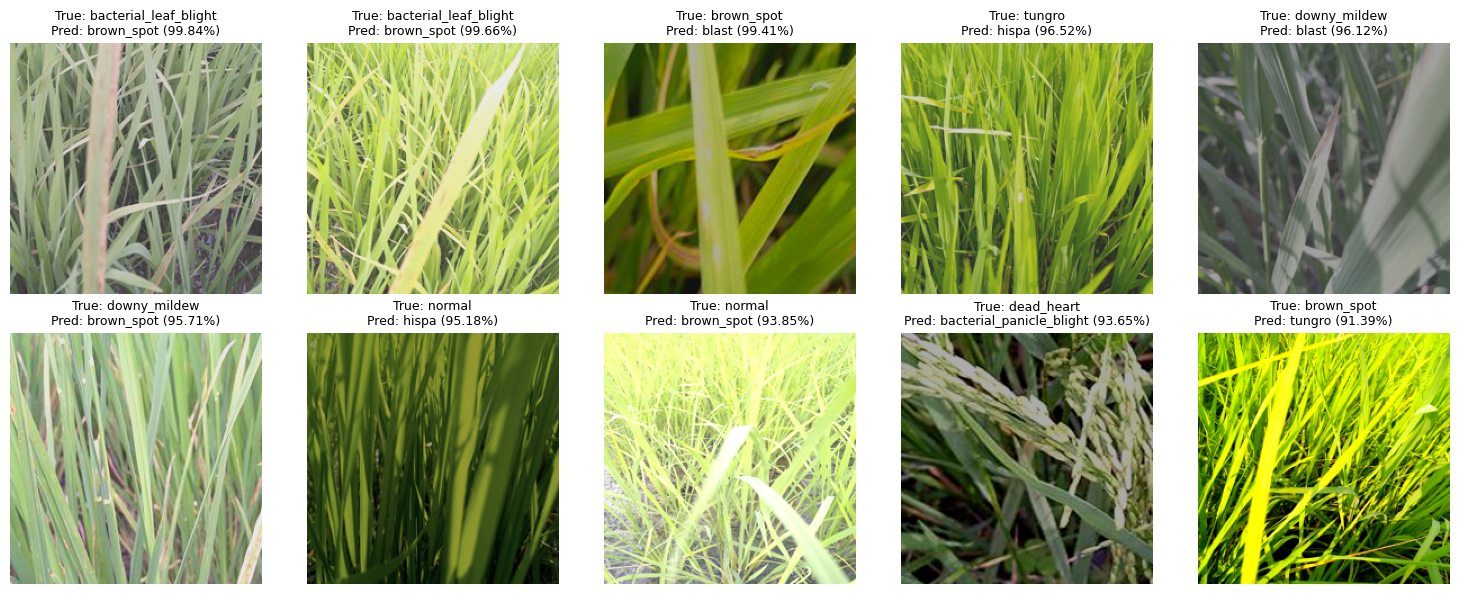

In [20]:

@torch.no_grad()
def get_all_preds_probs_targets(model, loader):
    model.eval()
    all_imgs = []
    all_probs = []
    all_preds = []
    all_targs = []
    for xb, yb in loader:
        xb = xb.to(device)
        logits = model(xb)
        # convert logits to probabilities using softmax
        probs = F.softmax(logits, dim=1)
        # get the predicted class (highest probability) and its confidence
        confs, preds = probs.max(dim=1)

        all_imgs.append(xb.cpu())
        all_probs.append(confs.cpu())
        all_preds.append(preds.cpu())
        all_targs.append(yb)

    # concatenate all batches into single tensors
    all_imgs = torch.cat(all_imgs)
    all_probs = torch.cat(all_probs)
    all_preds = torch.cat(all_preds)
    all_targs = torch.cat(all_targs)
    return all_imgs, all_probs, all_preds, all_targs

# Run inference on the test set (reusing test_loader from earlier cells)
imgs_all, confs_all, preds_all, targs_all = get_all_preds_probs_targets(model, test_loader)

# Find indices where the prediction was WRONG
wrong_mask = preds_all != targs_all
wrong_indices = torch.nonzero(wrong_mask).squeeze(1)

# Among the wrong predictions, sort by confidence (descending) to find the most "confidently wrong"
wrong_confs = confs_all[wrong_indices]
sorted_order = torch.argsort(wrong_confs, descending=True)
top10_idx = wrong_indices[sorted_order[:10]]

# Prepare mean/std for un-normalizing images (reusing config from earlier)
mean = torch.tensor(config['mean']).view(3, 1, 1)
std = torch.tensor(config['std']).view(3, 1, 1)

# Plot the top 10 most confidently wrong images
cols = 5
rows = int(np.ceil(len(top10_idx) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = axes.flatten()

for i, idx in enumerate(top10_idx):
    ax = axes[i]
    img = imgs_all[idx] * std + mean  # unnormalize
    npimg = img.numpy().transpose(1, 2, 0)
    npimg = np.clip(npimg, 0, 1)

    true_label = class_names[targs_all[idx].item()]
    pred_label = class_names[preds_all[idx].item()]
    confidence = confs_all[idx].item()

    ax.imshow(npimg)
    ax.set_title(f"True: {true_label}\nPred: {pred_label} ({confidence:.2%})", fontsize=9)
    ax.axis('off')

# hide any unused subplot axes
for j in range(len(top10_idx), rows * cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## Grad-CAM visualization for the top-10 most confidently wrong images

Uses existing variables: model, test_ds, top10_idx, imgs_all, targs_all, preds_all, confs_all, config, class_names, device

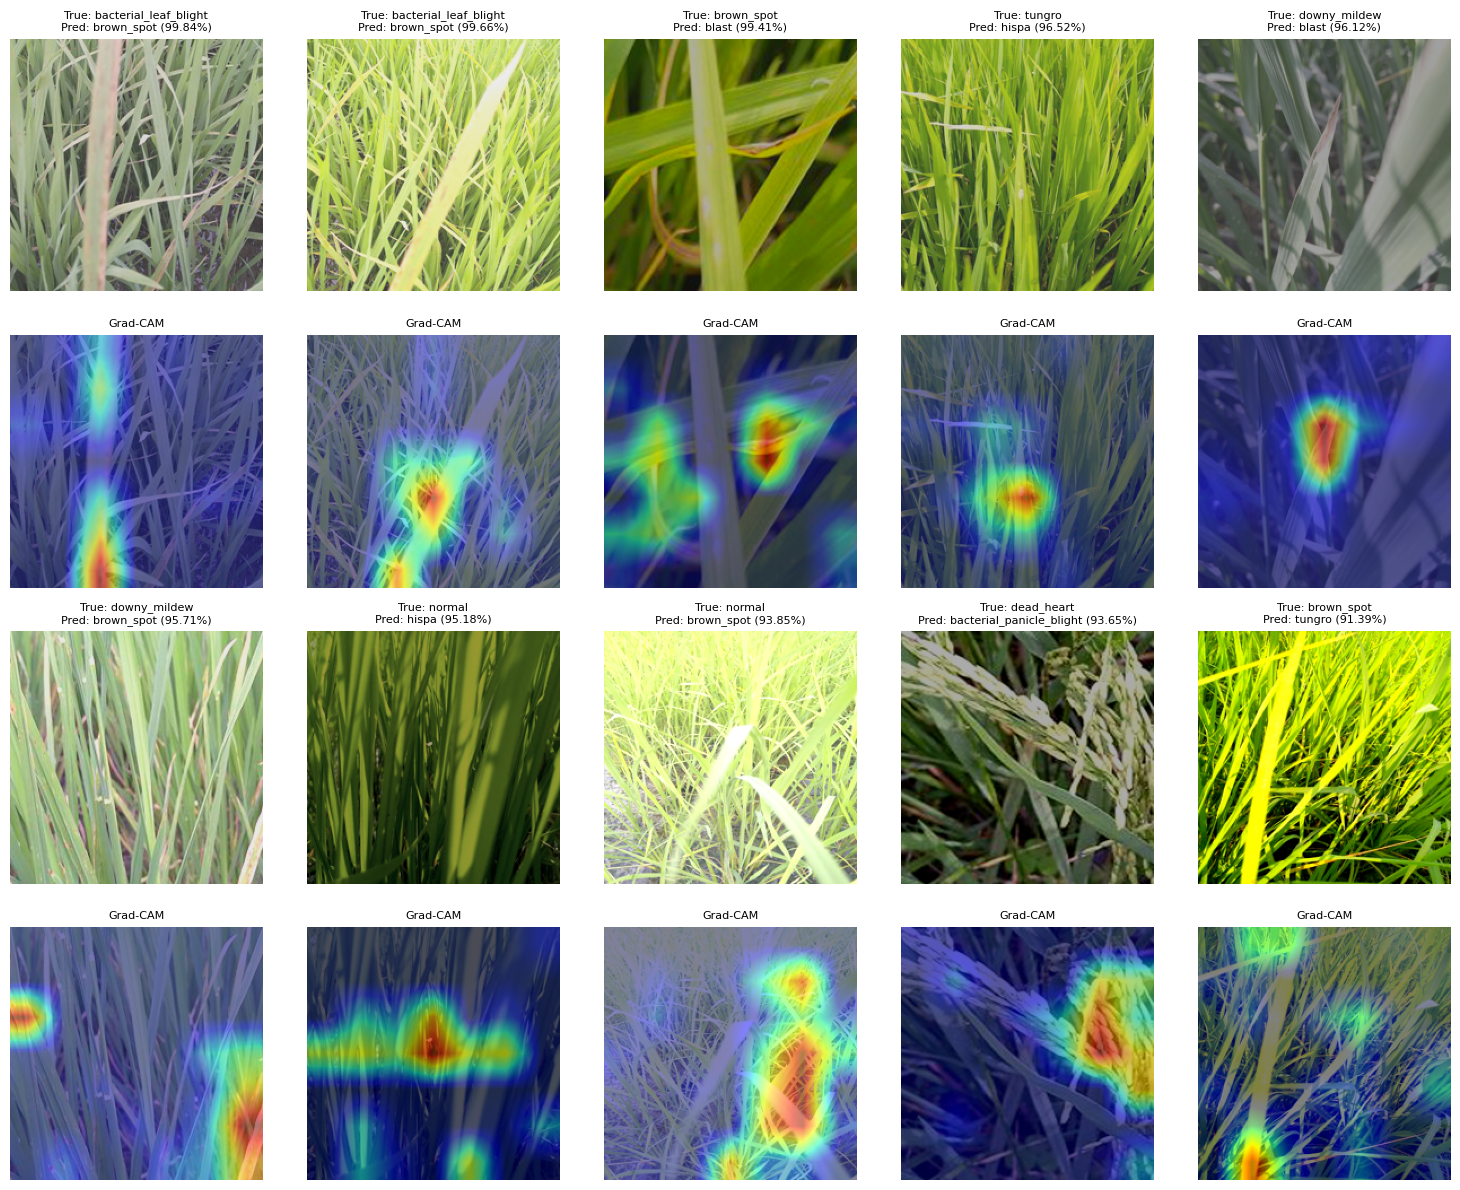

In [21]:
import torch.nn.functional as F

class GradCAM:
    """Simple Grad-CAM for CNN-style models (uses last conv feature map)."""
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.target_layer.register_forward_hook(self._save_activation)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()
        # tensor hook on the output fires even if earlier layers are frozen
        if output.requires_grad:
            output.register_hook(self._save_gradient)

    def _save_gradient(self, grad):
        self.gradients = grad.detach()

    def __call__(self, x, class_idx):
        self.model.zero_grad()
        with torch.enable_grad():
            x = x.clone().requires_grad_(True)
            logits = self.model(x)
            score = logits[0, class_idx]
            score.backward()

        # global-average-pool gradients -> weights
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        cam -= cam.min()
        if cam.max() > 0:
            cam /= cam.max()
        return cam

# find last conv layer automatically (resnet: layer4[-1])
target_layer = model.layer4[-1] if hasattr(model, 'layer4') else list(model.children())[-3]
gradcam = GradCAM(model, target_layer)

mean = torch.tensor(config['mean']).view(3, 1, 1)
std = torch.tensor(config['std']).view(3, 1, 1)

cols = 5
rows = int(np.ceil(len(top10_idx) / cols)) * 2  # image row + cam row pair
fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))

for i, idx in enumerate(top10_idx):
    r, c = divmod(i, cols)
    img_row = r * 2
    cam_row = r * 2 + 1

    img_t = imgs_all[idx].unsqueeze(0).to(device)
    img_t.requires_grad_(False)

    pred_class = preds_all[idx].item()
    true_class = targs_all[idx].item()

    cam = gradcam(img_t, pred_class)

    img_unnorm = imgs_all[idx] * std + mean
    npimg = img_unnorm.numpy().transpose(1, 2, 0)
    npimg = np.clip(npimg, 0, 1)

    ax_img = axes[img_row, c]
    ax_img.imshow(npimg)
    ax_img.set_title(f"True: {class_names[true_class]}\nPred: {class_names[pred_class]} ({confs_all[idx]:.2%})", fontsize=8)
    ax_img.axis('off')

    ax_cam = axes[cam_row, c]
    ax_cam.imshow(npimg)
    ax_cam.imshow(cam, cmap='jet', alpha=0.5)
    ax_cam.set_title("Grad-CAM", fontsize=8)
    ax_cam.axis('off')

# hide unused axes
for i in range(len(top10_idx), (rows // 2) * cols):
    r, c = divmod(i, cols)
    axes[r * 2, c].axis('off')
    axes[r * 2 + 1, c].axis('off')

plt.tight_layout()
plt.show()